# Corporate Bankruptcy Prediction

A reproducible inspection of the committed experiment. Run the main experiment with `python run.py train` from the repository root. This notebook loads those saved results and visualizations, so there is one source of truth. Team members and IDs: ____________________ / ____________________.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd()/"run.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
from bankruptcy.data import load_dataset, FEATURES
data, audit = load_dataset(ROOT/"data/raw/3year.arff")
display(pd.Series(audit, name="Data audit"))

raw_rows                                                                10503
raw_positive                                                              495
exact_duplicates_removed                                                   87
conflicting_rows_removed                                                    0
clean_rows                                                              10416
clean_positive                                                            493
features                                                                   64
missing_cells                                                            9833
sha256                      662617d2f90bfd17223595e50a0ac7007f9ee7915cfb51...
Name: Data audit, dtype: object

## Data quality and imbalance
Exact duplicate removal precedes splitting. Missing features are retained for fold-specific imputation or native handling by histogram boosting.

X37    0.451517
X21    0.077285
X27    0.068452
X60    0.056548
X45    0.056452
X24    0.021793
X54    0.021601
X28    0.021601
X64    0.021601
X53    0.021601
Name: missing_fraction, dtype: float64

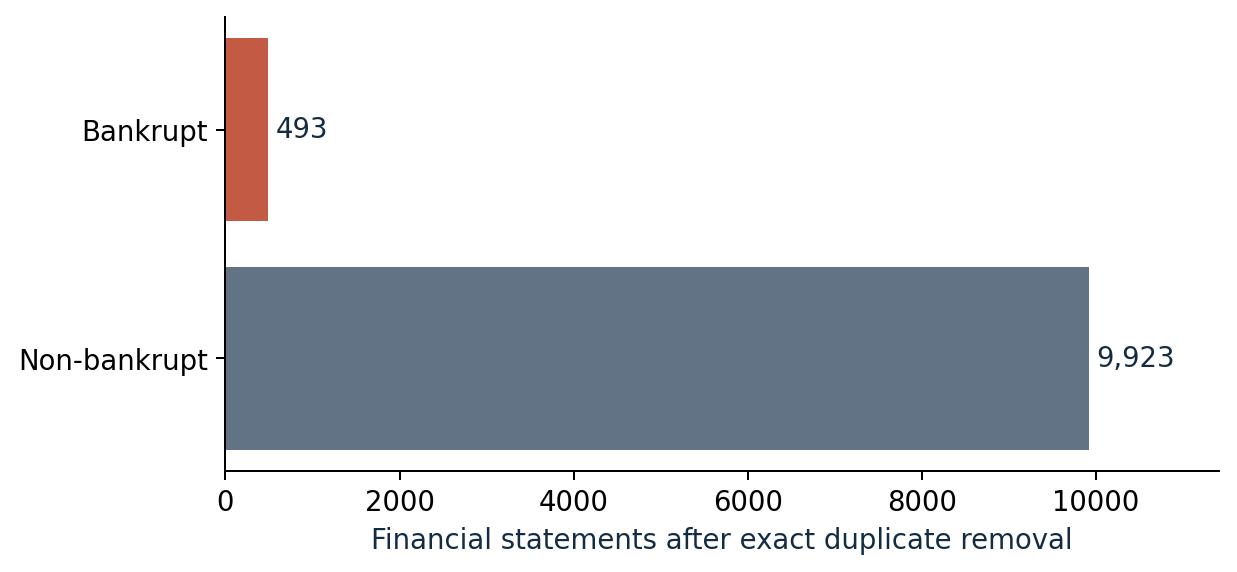

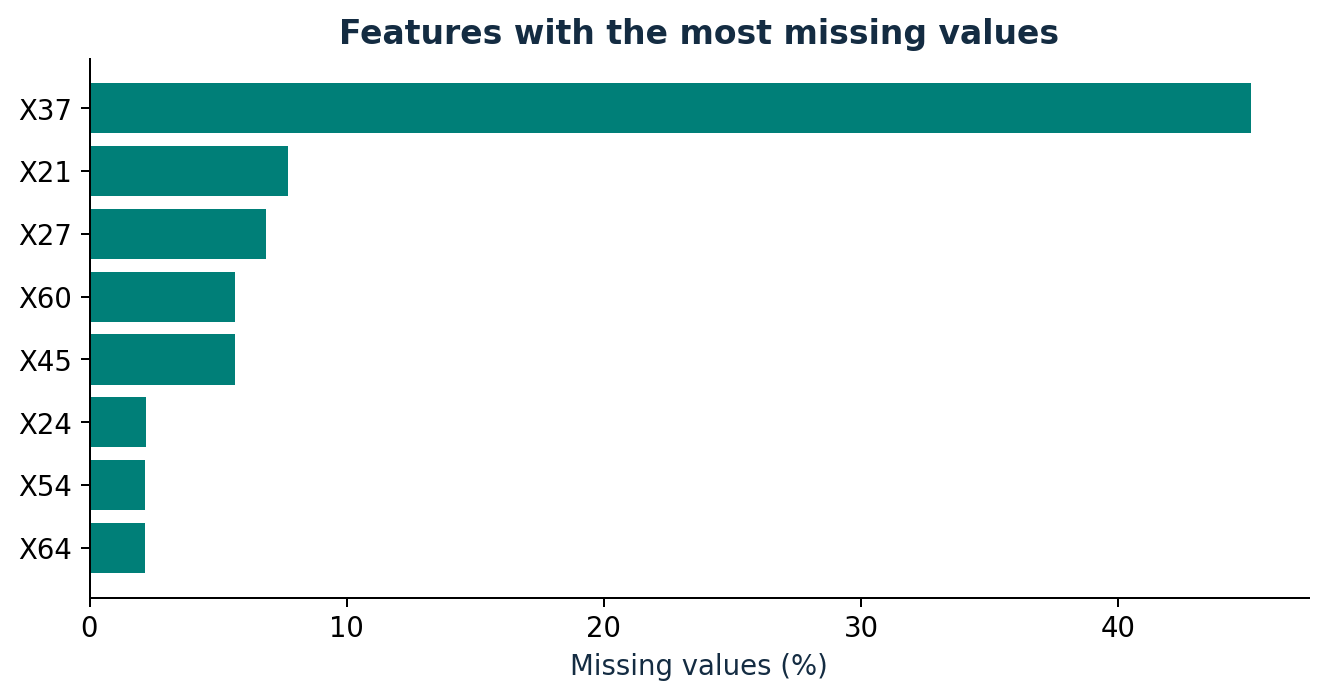

In [2]:
display(data[FEATURES].isna().mean().sort_values(ascending=False).head(10).rename("missing_fraction"))
display(Image(filename=str(ROOT/"reports/figures/class_balance.png")))
display(Image(filename=str(ROOT/"reports/figures/missing_values.png")))

## Model selection
All six candidates use the same three development folds. The highest mean average precision determines the winner; the test set has no role in selection.

,model,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,seconds
0,Histogram gradient boosting,0.618830,0.036790,0.913963,6.68
1,Random forest,0.433725,0.036766,0.868324,20.32
2,RBF support vector machine,0.421928,0.052698,0.873033,30.65
3,Extra trees,0.382847,0.049613,0.852059,6.55
4,Logistic regression,0.297292,0.007787,0.871033,1.16
5,Gaussian naive Bayes,0.087235,0.033540,0.676451,0.43


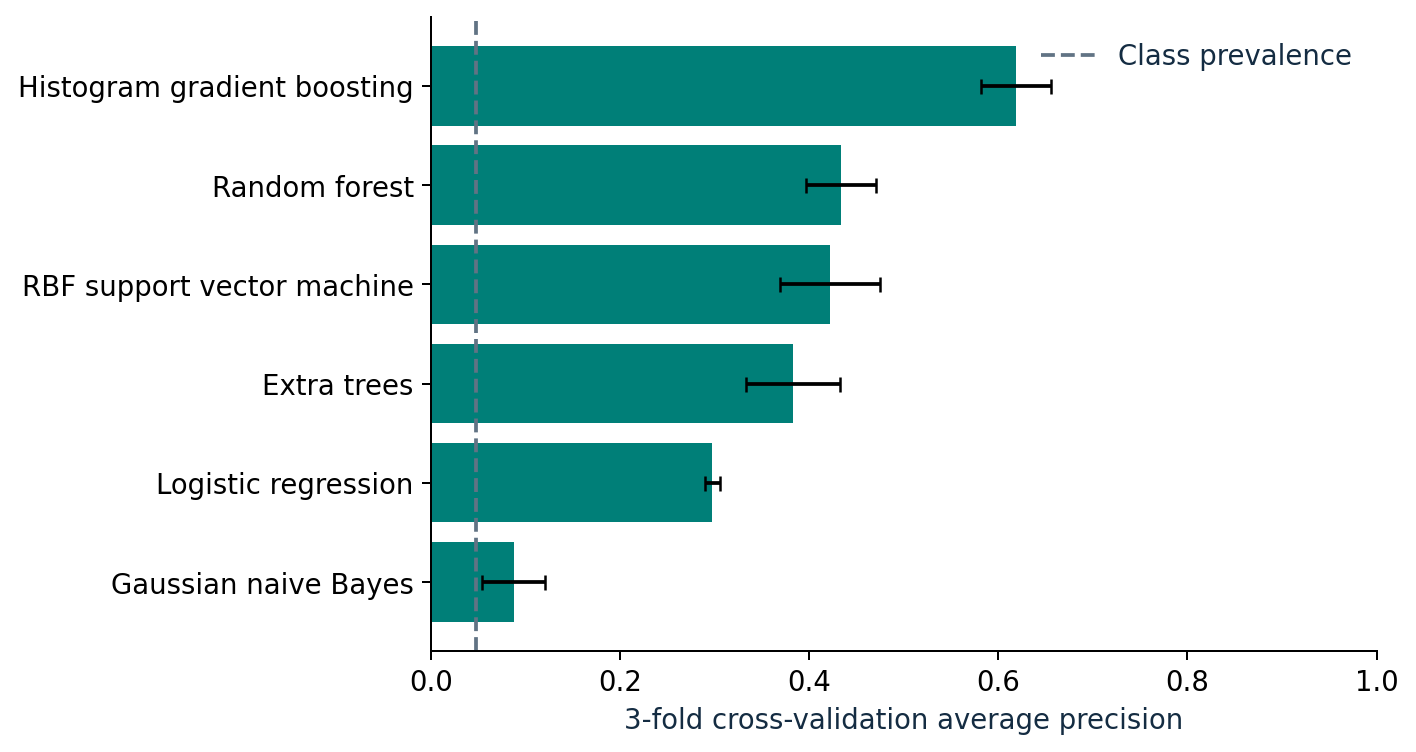

In [3]:
comparison = pd.read_csv(ROOT/"reports/model_comparison.csv")
display(comparison)
display(Image(filename=str(ROOT/"reports/figures/model_comparison.png")))

## Threshold choice
The threshold maximizes F2 on development out-of-fold predictions. It prioritizes recall, without claiming a real monetary cost ratio.

Selected model: Histogram gradient boosting
Threshold: 0.19795169777758606


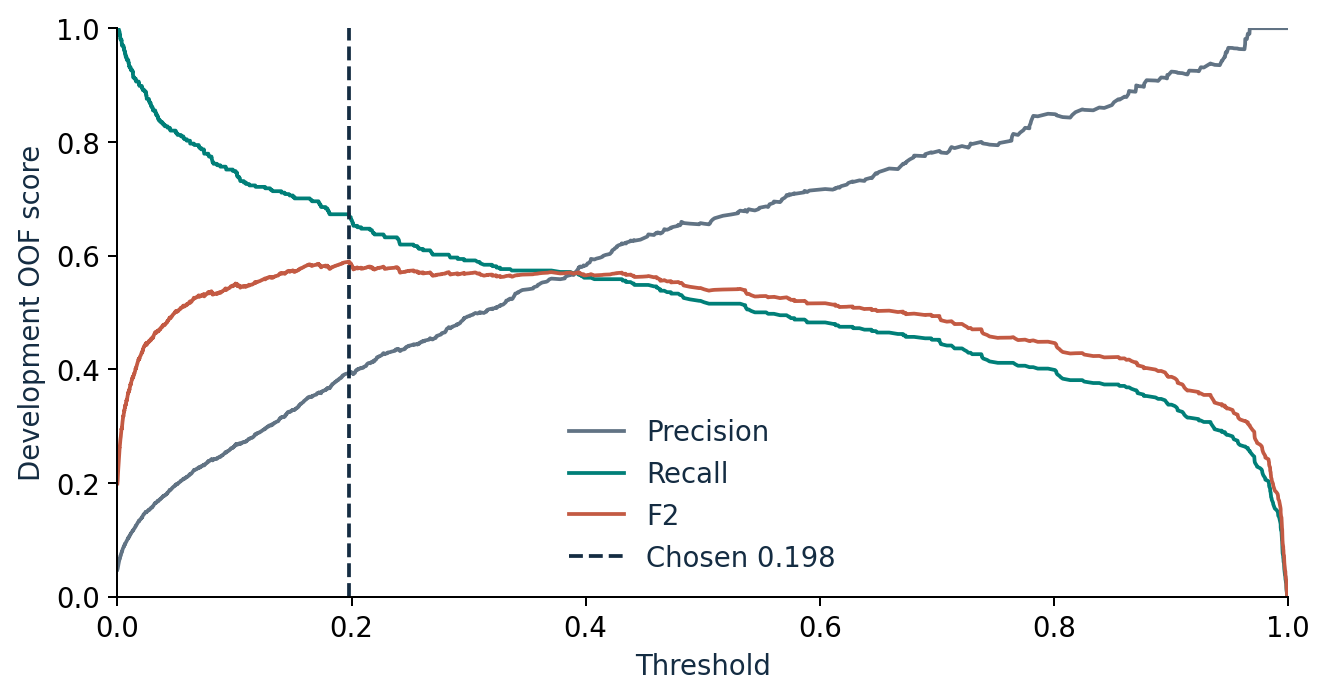

In [4]:
report = json.loads((ROOT/"reports/metrics.json").read_text())
print("Selected model:", report["selected_model"])
print("Threshold:", report["test"]["threshold"])
display(Image(filename=str(ROOT/"reports/figures/threshold_tradeoff.png")))

## Independent test results
The test set remains untouched until the model and threshold are fixed. Bootstrap intervals condition on this model and split.

,selected_threshold,default_0.5
threshold,0.197952,0.5
accuracy,0.915547,0.96785
balanced_accuracy,0.883688,0.834366
precision,0.342857,0.653846
recall,0.848485,0.686869
f1,0.488372,0.669951
f2,0.655226,0.68
average_precision,0.749519,0.749519
roc_auc,0.967743,0.967743


,2.5%,97.5%
precision,0.310687,0.386667
recall,0.777778,0.919192
f2,0.606560,0.707497
average_precision,0.683148,0.819546
roc_auc,0.955911,0.980073


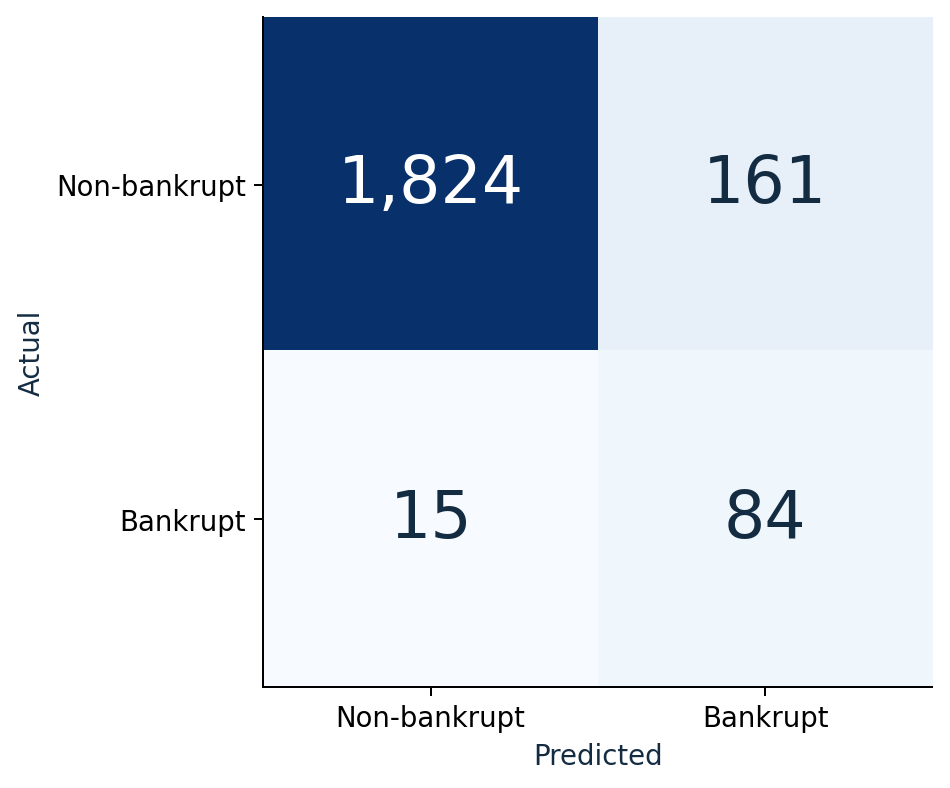

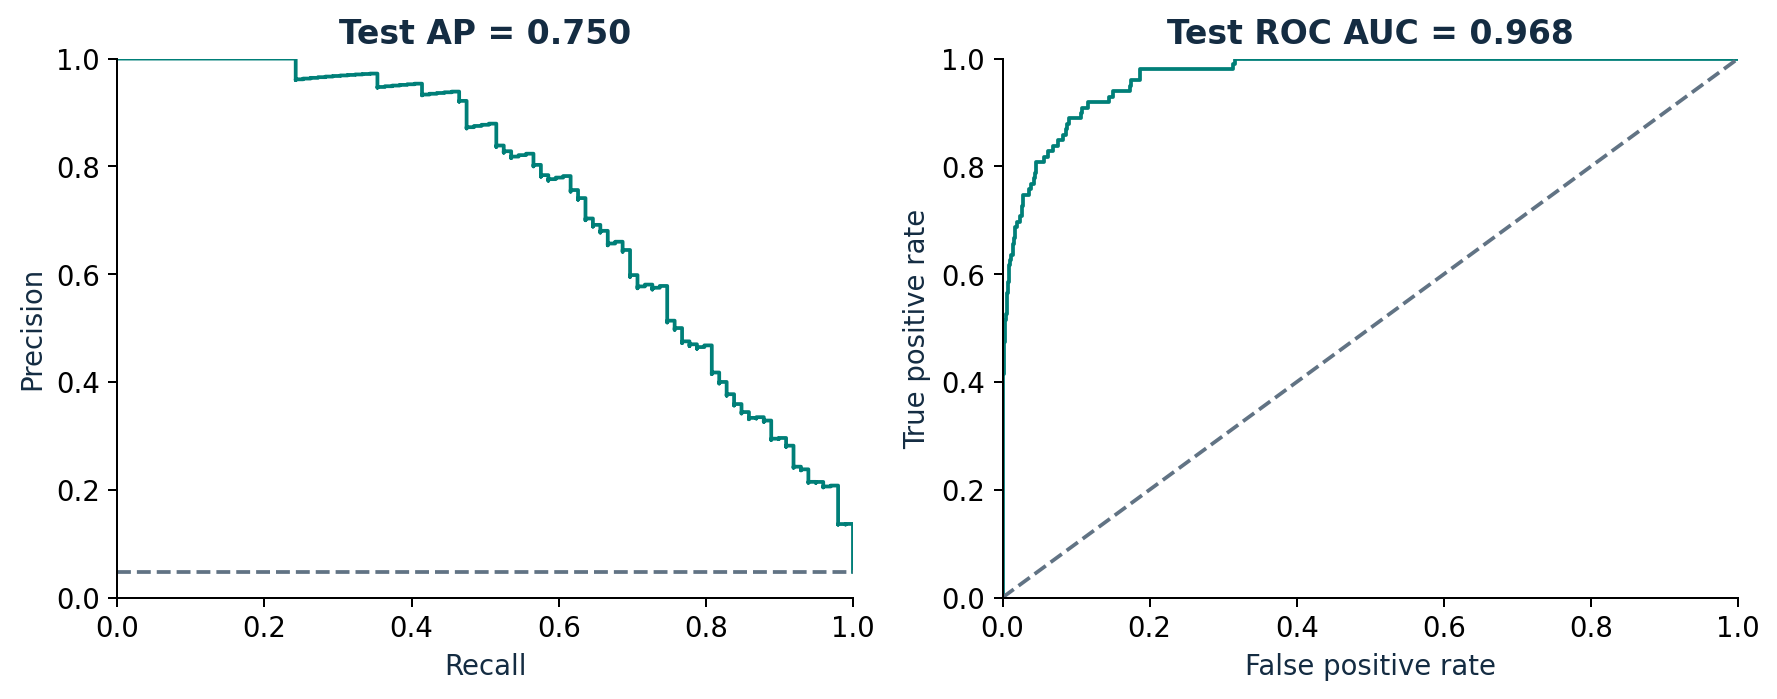

In [5]:
display(pd.DataFrame({"selected_threshold":report["test"], "default_0.5":report["test_default_threshold"]}).drop(index="confusion_matrix"))
display(pd.DataFrame(report["bootstrap_95_intervals"], index=["2.5%","97.5%"]).T)
display(Image(filename=str(ROOT/"reports/figures/confusion_matrix.png")))
display(Image(filename=str(ROOT/"reports/figures/pr_roc.png")))

## Interpretation and demonstration
Permutation importance is descriptive, not causal. Correlated ratios can make it unstable. The default threshold has higher test F2 in this particular split, but changing the selected threshold after seeing the test would bias the experiment.

In [6]:
display(pd.read_csv(ROOT/"reports/feature_importance.csv").head(10))
from bankruptcy.predict import load_bundle, predict_frame
sample=pd.read_csv(ROOT/"examples/sample_companies.csv")
display(predict_frame(load_bundle(ROOT),sample))

,feature,importance_mean,importance_std
0,X27,0.546727,0.031352
1,X34,0.266484,0.012081
2,X46,0.140734,0.013574
3,X58,0.085162,0.010855
4,X21,0.072939,0.001933
5,X5,0.072911,0.001989
6,X56,0.041274,0.006272
7,X39,0.037878,0.002186
8,X26,0.031701,0.005391
9,X42,0.021150,0.003694


,row,risk_score,threshold,predicted_bankrupt,missing_features
0,1,0.081452,0.197952,0,2
1,2,0.003971,0.197952,0,0
2,3,0.003244,0.197952,0,0
3,4,0.039786,0.197952,0,3
4,5,0.002372,0.197952,0,1
5,6,0.002679,0.197952,0,0
6,7,0.068496,0.197952,0,1
7,8,0.000571,0.197952,0,1
8,9,0.001386,0.197952,0,2
9,10,0.003429,0.197952,0,0


## Limitations and next steps
The data is historical and company IDs are unavailable. Exact duplicate removal cannot ensure company-disjoint or temporal validation. Future work should add group/date information, measure threshold stability, and calibrate scores on independent data.

Dataset: Tomczak (2016), UCI, https://doi.org/10.24432/C5F600. Full references: `docs/references.md`.